In [1]:
import pandas as pd
import numpy as np
import os
import pickle
from datetime import datetime
import matplotlib.pyplot as plt

In [2]:
cwd = os.getcwd()
# print(cwd)

In [3]:
pickle_folder = r'E:\VK_data\data_for_yc_active'
df_sensors = pd.read_pickle(os.path.join(pickle_folder, 'df_sensors.pkl'))

# display(df_sensors)

In [4]:
df = df_sensors[df_sensors['popularName'].str.contains(r'(?=.*Bö)(?=.*VS02)', na=False, regex=True)]
name = df[['popularName', 'deviceMeasurementUnit']]
Mbus_id = df['id'].values
display(name)

,popularName,deviceMeasurementUnit
564,Styrpinnen 15•AS0102•VS02•Börvärden GT11 Aktue...,https://w3id.org/rec/core/Celsius
568,Styrpinnen 15•AS0102•VS02•Börvärden GP11 Tryck...,https://w3id.org/rec/core/Pascal
620,Styrpinnen 15•AS0102•VS02•Börvärden GT11 Kurva,https://w3id.org/rec/core/Celsius


In [5]:
pickle_data = r'E:\VK_data\2026-01-01'
sensor_id = Mbus_id
sensor_meta = (
    df_sensors.loc[df_sensors["id"].isin(sensor_id), ["id", "popularName"]]
    .drop_duplicates(subset="id")
    .reset_index(drop=True)
)

# Add KB02 and VS02 sensors and remove duplicate IDs


sensor_meta = (
    df_sensors.loc[
        df_sensors["id"].isin(sensor_id),
        ["id", "popularName", "littera"]
    ]
    .drop_duplicates(subset="id")
    .reset_index(drop=True)
)

sensor_meta["key"] = sensor_meta["popularName"].str.split().str[-1]


dfs = {}

for sid, key in sensor_meta[["id", "key"]].itertuples(index=False, name=None):
    csv_path = os.path.join(pickle_data, f"timeseries_{sid}.csv")

    if os.path.exists(csv_path):
        df_in = pd.read_csv(csv_path)
        df_in = df_in.copy()
        df_in.index = pd.to_datetime(df_in["observationTime"], format="mixed")
        dfs[key] = df_in
    else:
        print(f"Missing file for {key} ({sid})")

for key, d in dfs.items():
    print(key, d.shape)


börvärde (5948421, 2)
Tryckbörvärde (142225, 2)
Kurva (2751633, 2)


In [6]:
df = df_sensors[df_sensors['popularName'].str.contains(r'(?=.*VS02)(?=.*temperatur)', na=False, regex=True)]
name = df[['popularName', 'deviceMeasurementUnit']]
VS02_id = df['id'].values

# display(name)

In [7]:
df = df_sensors[df_sensors['popularName'].str.contains(r'(?=.*KB02)(?=.*temperatur)', na=False, regex=True)]
name = df[['popularName', 'deviceMeasurementUnit']]
KB02_id = df['id'].values

# display(name)

In [8]:
df = df_sensors[df_sensors['popularName'].str.contains(r'(?=.*fukt)', na=False, regex=True)]
name = df[['popularName', 'deviceMeasurementUnit']]
humidity_id = df['id'].values

In [9]:
df = df_sensors[df_sensors['popularName'].str.contains(r'(?=.*VS02)(?=.*Flö)', na=False, regex=True)]
name = df[['popularName', 'deviceMeasurementUnit']]
heating_flow_id = df['id'].values

In [10]:
df = df_sensors[df_sensors['popularName'].str.contains(r'(?=.*KB02)(?=.*Flö)', na=False, regex=True)]
name = df[['popularName', 'deviceMeasurementUnit']]
cooling_flow_id = df['id'].values

In [11]:
df = df_sensors[df_sensors['popularName'].str.contains(r'(?=.*07-D2-02)', na=False, regex=True)]
name = df[['popularName', 'deviceMeasurementUnit']]
sensor_id = df['id'].values

In [12]:
pickle_data = r'E:\VK_data\2026-01-01'

sensor_id = np.concatenate([sensor_id, humidity_id])

sensor_meta = (
    df_sensors.loc[df_sensors["id"].isin(sensor_id), ["id", "popularName"]]
    .drop_duplicates(subset="id")
    .reset_index(drop=True)
)

sensor_id = pd.unique(np.concatenate([sensor_id, KB02_id, VS02_id, heating_flow_id, cooling_flow_id]))

sensor_meta = (
    df_sensors.loc[
        df_sensors["id"].isin(sensor_id),
        ["id", "popularName", "littera"]
    ]
    .drop_duplicates(subset="id")
    .reset_index(drop=True)
)

sensor_meta["key"] = sensor_meta["popularName"].str.split().str[-1]

for family, ids in [("VS02", VS02_id), ("KB02", KB02_id)]:
    for sid in ids:
        littera = sensor_meta.loc[sensor_meta["id"].eq(sid), "littera"].iloc[0]
        role = "supply" if str(littera).endswith("STEMP") else "return"
        sensor_meta.loc[sensor_meta["id"].eq(sid), "key"] = f"{family}_{role}"

for flow_key, ids in [("heating_flow", heating_flow_id), ("cooling_flow", cooling_flow_id)]:
    if len(ids) != 1:
        print(f"Warning: {flow_key} matched {len(ids)} sensors:")
        print(df_sensors.loc[df_sensors["id"].isin(ids), ["id", "popularName"]])
    for i, sid in enumerate(ids):
        key = flow_key if len(ids) == 1 else f"{flow_key}_{i}"
        sensor_meta.loc[sensor_meta["id"].eq(sid), "key"] = key

display(sensor_meta[["id", "key", "popularName"]])

dfs = {}

for sid, key in sensor_meta[["id", "key"]].itertuples(index=False, name=None):
    csv_path = os.path.join(pickle_data, f"timeseries_{sid}.csv")

    if os.path.exists(csv_path):
        df_in = pd.read_csv(csv_path)
        df_in = df_in.copy()
        df_in.index = pd.to_datetime(df_in["observationTime"], format="mixed")
        dfs[key] = df_in
    else:
        print(f"Missing file for {key} ({sid})")

for key, d in dfs.items():
    print(key, d.shape)


,id,key,popularName
0,16dc71bf-4fbf-436a-a887-c2036a5fd66d,börvärde,Styrpinnen 15•Plan 7•LB0101•07-D2-02 GT11 Akti...
1,2b091703-ae35-45a1-8f13-4dc32fa37c66,Kylställdon,Styrpinnen 15•Plan 7•LB0101•07-D2-02 SV4x Kyls...
2,c1324d62-aeb4-4b1c-b9b0-54981fd2155a,Koldioxidgivare,Styrpinnen 15•Plan 7•LB0101•07-D2-02 GQ41 Kold...
3,b79ab65b-426e-421f-8121-6701df56a66c,VAVutgång,Styrpinnen 15•Plan 7•LB0101•07-D2-02 ST4x VAVu...
4,56fa0ce7-f566-46ff-af32-b18dfb6ea79a,Värmeställdon,Styrpinnen 15•Plan 7•LB0101•07-D2-02 SV2x Värm...
5,beea8fc4-c2d9-427a-88a9-2603d31429b6,Rumstemperatur,Styrpinnen 15•Plan 7•LB0101•07-D2-02 GT11 Rums...
6,e087b48c-7a75-4a95-b772-5e65544b2b79,cooling_flow,Styrpinnen 15•AS0102•Mbus•KB02-MQ44 KB02-MQ44 ...
7,24fdf806-8110-4252-8413-0a0d0fe620fc,VS02_supply,Styrpinnen 15•AS0102•Mbus•VS02-MQ42 VS02-MQ42 ...
8,b14dabd9-2916-4d91-8189-698ac26c9357,VS02_return,Styrpinnen 15•AS0102•Mbus•VS02-MQ42 VS02-MQ42 ...
9,47ca6f29-759f-46c1-88f4-78636e6e7d9c,KB02_supply,Styrpinnen 15•AS0102•Mbus•KB02-MQ44 KB02-MQ44 ...


börvärde (173743, 2)
Kylställdon (423899, 2)
Koldioxidgivare (512574, 2)
VAVutgång (411886, 2)
Värmeställdon (177034, 2)
Rumstemperatur (496480, 2)
cooling_flow (335932, 2)
VS02_supply (968052, 2)
VS02_return (747589, 2)
KB02_supply (960338, 2)
KB02_return (851860, 2)
heating_flow (680709, 2)
fukt (236754, 2)


In [13]:
T_out_csv = './smhi_Tout.csv'
solar_csv = './smhi_solar.csv'

def read_smhi_csv(path, value_col=None):
    raw = pd.read_csv(path, sep=None, engine='python', comment='#', decimal=',')

    # Find date/time columns (e.g. "Datum" and "Tid (UTC)")
    date_col = next((c for c in raw.columns if 'date' in c.lower()), None)
    time_col = next((c for c in raw.columns if 'time' in c.lower()), None)

    if date_col is None:
        date_col = next(
            (c for c in raw.columns if 'observationtime' in c.lower() or 'datetime' in c.lower()),
            None
        )
        if date_col is None:
            raise ValueError(f'Could not find a date/time column in {path}')

    if time_col and time_col != date_col:
        timestamps = pd.to_datetime(
            raw[date_col].astype(str) + ' ' + raw[time_col].astype(str),
            errors='coerce'
        )
    else:
        timestamps = pd.to_datetime(raw[date_col], errors='coerce')

    if value_col is None:
        candidates = [
            c for c in raw.columns
            if c not in {date_col, time_col}
            and not any(word in c.lower() for word in ('kvalitet', 'quality', 'station'))
        ]
        numeric = {
            c: pd.to_numeric(raw[c], errors='coerce')
            for c in candidates
        }
        value_col = next((c for c, values in numeric.items() if values.notna().any()), None)
        if value_col is None:
            raise ValueError(f'Could not find a numeric measurement column in {path}')
        values = numeric[value_col]
    else:
        values = pd.to_numeric(raw[value_col], errors='coerce')

    result = pd.DataFrame({'value': values.to_numpy()}, index=timestamps)
    result.index.name = 'datetime'
    result = result.loc[result.index.notna()].sort_index()
    result = result[~result.index.duplicated(keep='first')]

    target_index = pd.date_range(
        start=result.index.min().ceil('30min'),
        end=result.index.max().floor('30min'),
        freq='30min'
    )
    result = (
        result.reindex(result.index.union(target_index))
              .sort_index()
              .interpolate(method='time')
              .reindex(target_index)
    )
    return result.loc[result.index.notna()].sort_index()


df_T_out = read_smhi_csv(T_out_csv)
df_solar = read_smhi_csv(solar_csv)
df_cloud = read_smhi_csv('smhi_cloud.csv')
df_humidity = read_smhi_csv('smhi_humidity.csv')

In [14]:
# fig, ax = plt.subplots(figsize=(12, 5))

# for date, label in [('2024-08-12', 'Aug 12'), ('2024-08-22', 'Aug 22')]:
#     daily = dfs['KB02_supply'].loc[date]
#     time_of_day = (
#         daily.index.hour
#         + daily.index.minute / 60
#         + daily.index.second / 3600
#     )
#     ax.plot(time_of_day, daily['value'], marker='.', label=label)

# ax.set_title('Supply temperature')
# ax.set_xlabel('Time of day')
# ax.set_ylabel('Value')
# ax.set_xticks(range(0, 24, 2))
# ax.set_xlim(0, 24)
# ax.legend()
# plt.show()

In [15]:
rename_map = {
    'börvärde': 'setpoint',
    'Kylställdon': 'cooling_valve',
    'Koldioxidgivare': 'co2',
    'VAVutgång': 'VAV',
    'Värmeställdon': 'heating_valve',
    'Rumstemperatur': 'indoor_temperature',
    'fukt': 'humidity',
}
dfs = {rename_map.get(k, k): v for k, v in dfs.items()}
print(dfs.keys())

dict_keys(['setpoint', 'cooling_valve', 'co2', 'VAV', 'heating_valve', 'indoor_temperature', 'cooling_flow', 'VS02_supply', 'VS02_return', 'KB02_supply', 'KB02_return', 'heating_flow', 'humidity'])


In [16]:
dfs['outdoor_temperature'] = df_T_out
dfs['solar_radiation'] = df_solar

In [17]:
print(dfs.keys())

dict_keys(['setpoint', 'cooling_valve', 'co2', 'VAV', 'heating_valve', 'indoor_temperature', 'cooling_flow', 'VS02_supply', 'VS02_return', 'KB02_supply', 'KB02_return', 'heating_flow', 'humidity', 'outdoor_temperature', 'solar_radiation'])


In [18]:
start_date = '2023-10-01 00:00:00'
end_date = '2024-10-01 00:00:00'

In [19]:
def time_weighted_resample(df, start_date, end_date, freq, window=None, value_cols=None,
                           ffill_cols=('setpoint',)):
    df = df.sort_index()
    df = df[~df.index.duplicated(keep='first')]

    if value_cols is None:
        value_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    ffill_cols = [c for c in (ffill_cols or []) if c in value_cols]

    target_times = pd.date_range(start=start_date, end=end_date, freq=freq)
    window = pd.Timedelta(freq) if window is None else pd.Timedelta(window)
    window_ns = window.value

    src_times = df.index.values.astype('datetime64[ns]').astype('int64')
    tgt_times = target_times.values.astype('datetime64[ns]').astype('int64')

    values = {col: df[col].to_numpy(dtype=float) for col in value_cols}
    result = {col: np.full(len(target_times), np.nan) for col in value_cols}

    lo_idx = np.searchsorted(src_times, tgt_times - window_ns, side='left')
    hi_idx = np.searchsorted(src_times, tgt_times + window_ns, side='right')

    for i, (lo, hi, t) in enumerate(zip(lo_idx, hi_idx, tgt_times)):
        if hi <= lo:
            continue
        dt = np.abs(src_times[lo:hi] - t).astype(float)
        w = np.clip(1.0 - dt / window_ns, 0, None)
        for col in value_cols:
            v = values[col][lo:hi]
            mask = ~np.isnan(v)
            wsum = w[mask].sum()
            if wsum > 0:
                result[col][i] = np.dot(v[mask], w[mask]) / wsum

    # Fill gaps with the last observed source value at or before each target time
    for col in ffill_cols:
        v = values[col]
        valid = ~np.isnan(v)
        v_times, v_vals = src_times[valid], v[valid]
        missing = np.isnan(result[col])
        if not missing.any() or len(v_vals) == 0:
            continue
        prev_idx = np.searchsorted(v_times, tgt_times[missing], side='right') - 1
        filled = np.where(prev_idx >= 0, v_vals[np.clip(prev_idx, 0, None)], np.nan)
        result[col][missing] = filled

    out = pd.DataFrame(result, index=target_times)
    out.index.name = df.index.name or 'time'

    return out

In [20]:
ffill_keys = ['setpoint', 'co2']

for key in dfs.keys():
    df_resampled = time_weighted_resample(dfs[key], start_date, end_date, freq='30min', window='30min')
    if key in ffill_keys:
        df_resampled = df_resampled.ffill()
    dfs[key] = df_resampled

In [21]:
export_folder = '07-D2-02_data'
os.makedirs(os.path.join(cwd, export_folder), exist_ok=True)

export_path = os.path.join(cwd, export_folder, 'dfs.pkl')
with open(export_path, 'wb') as f:
    pickle.dump(dfs, f)

print(f'Exported dfs to {export_path}')

Exported dfs to c:\Users\yangzhec\OneDrive - KTH\Projects\TwinVista\vk_project\New_VK\07-D2-02_data\dfs.pkl


In [22]:
# dfs['humidity']['value'].plot()

In [23]:
# from scipy import stats

# humidity = dfs['humidity']['2024-06-01':'2024-09-01']
# indoor_temperature = dfs['indoor_temperature']['2024-06-01':'2024-09-01']
# paired = pd.concat(
#     [
#         humidity['value'].rename('humidity'),
#         indoor_temperature['value'].rename('indoor_temperature')
#     ],
#     axis=1
# ).dropna()

# pearson_r, pearson_p = stats.pearsonr(
#     paired['humidity'], paired['indoor_temperature']
# )
# spearman_r, spearman_p = stats.spearmanr(
#     paired['humidity'], paired['indoor_temperature']
# )

# print(f"Paired observations: {len(paired)}")
# print(f"Pearson correlation:  r = {pearson_r:.3f}, p = {pearson_p:.3g}")
# print(f"Spearman correlation: ρ = {spearman_r:.3f}, p = {spearman_p:.3g}")

# fig, ax = plt.subplots(figsize=(7, 5))
# ax.scatter(paired['humidity'], paired['indoor_temperature'], alpha=0.3)
# ax.set_xlabel('Humidity')
# ax.set_ylabel('Indoor temperature')
# ax.set_title('Humidity vs. indoor temperature')
# plt.show()

<Axes: xlabel='observationTime'>

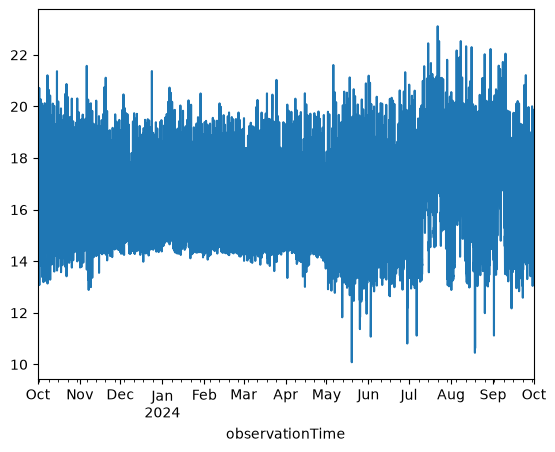

In [24]:
dfs['KB02_supply']['value'].plot()

In [25]:
print(dfs.keys())

dict_keys(['setpoint', 'cooling_valve', 'co2', 'VAV', 'heating_valve', 'indoor_temperature', 'cooling_flow', 'VS02_supply', 'VS02_return', 'KB02_supply', 'KB02_return', 'heating_flow', 'humidity', 'outdoor_temperature', 'solar_radiation'])
